In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lmr import load_routes
routes = load_routes(200)
df = pd.DataFrame([dict(n=len(r.T), station=r.station, score=r.score,
                        n_zones=len(r.zone_names), asym=np.abs(r.T - r.T.T).mean() / r.T.mean())
                   for r in routes])
df.describe()

,n,n_zones,asym
count,200.000000,200.000000,200.000000
mean,148.020000,20.160000,0.085493
std,32.560567,5.065838,0.040110
min,51.000000,5.000000,0.038060
25%,129.750000,16.750000,0.061475
50%,152.500000,20.000000,0.073980
75%,173.000000,24.000000,0.093769
max,206.000000,34.000000,0.307964


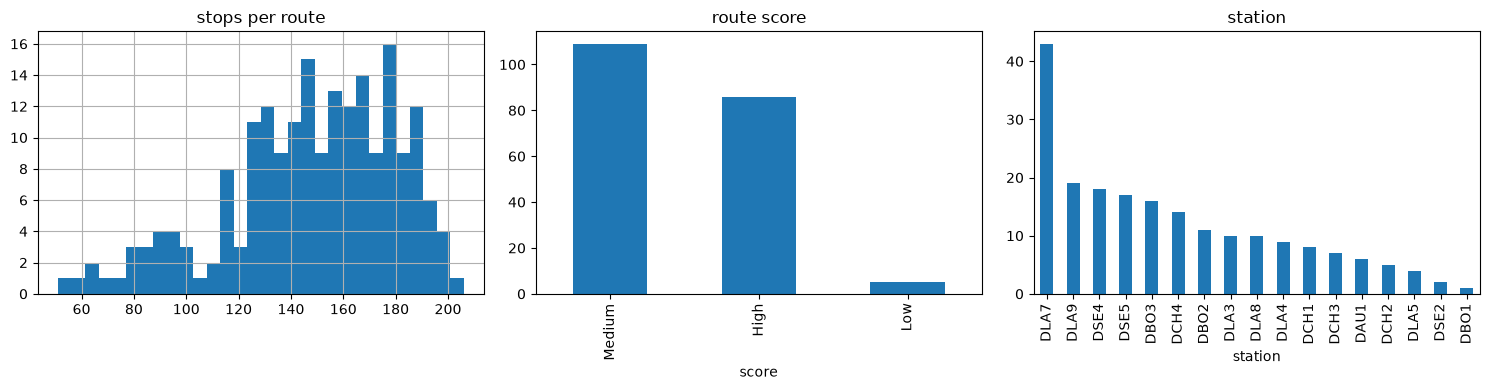

In [2]:
# cell 2: distributions
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.n.hist(ax=ax[0], bins=30); ax[0].set_title("stops per route")
df.score.value_counts().plot.bar(ax=ax[1], title="route score")
df.station.value_counts().plot.bar(ax=ax[2], title="station")
plt.tight_layout(); plt.show()

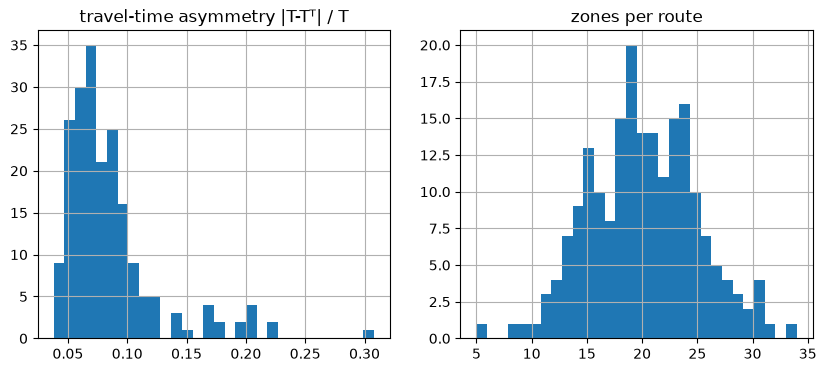

In [3]:
# cell 3: asymmetry and zones
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df.asym.hist(ax=ax[0], bins=30); ax[0].set_title("travel-time asymmetry |T-Tᵀ| / T")
df.n_zones.hist(ax=ax[1], bins=30); ax[1].set_title("zones per route")
plt.show()

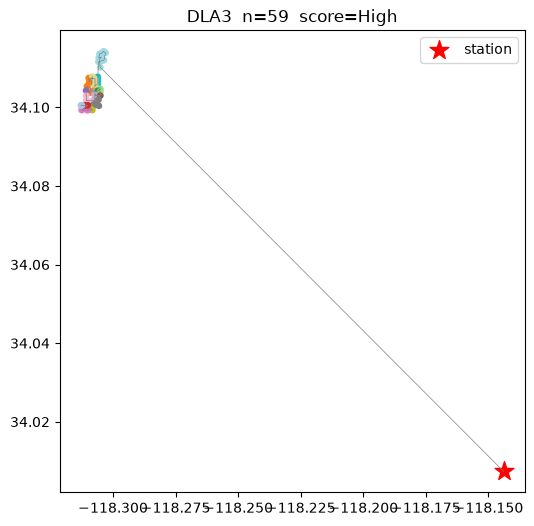

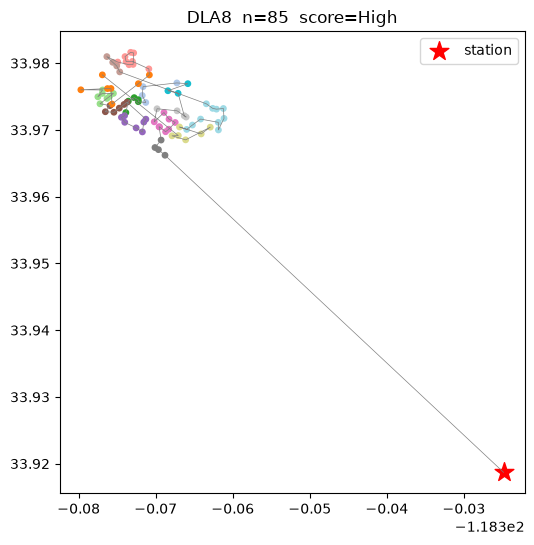

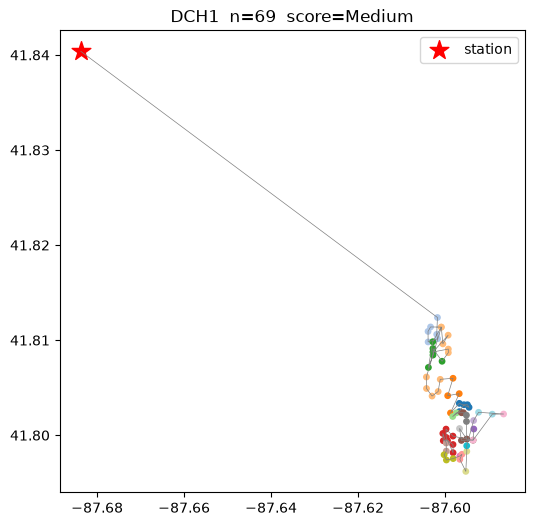

In [4]:
# cell 4: one route on a map; driver's path in order, coloured by zone
for r in routes[:3]:
    plt.figure(figsize=(6, 6))
    plt.plot(r.xy[:, 1], r.xy[:, 0], lw=0.5, c="gray")
    plt.scatter(r.xy[:, 1], r.xy[:, 0], c=r.zone, cmap="tab20", s=15)
    plt.scatter(*r.xy[0, ::-1], c="red", marker="*", s=200, label="station"); plt.legend()
    plt.title(f"{r.station}  n={len(r.T)}  score={r.score}"); plt.show()